# 🎮 Projet 1 — Prédiction du Churn des Joueurs en Ligne
**Master IADAIG — ENS Fès / USMBA — Année 2025/2026**  
**Dataset : Predict Online Gaming Behavior Dataset (Rabie El Kharoua, Kaggle)**

---

## Plan du Notebook
1. Import des bibliothèques  
2. Chargement & Exploration des données (EDA)  
3. Prétraitement & Feature Engineering  
4. Gestion du déséquilibre (SMOTE)  
5. Modélisation (Régression Logistique, Random Forest, XGBoost)  
6. Évaluation & Comparaison des modèles  
7. Résumé Final & Conclusion


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║       PROJET 1 — PRÉDICTION DU CHURN DES JOUEURS EN LIGNE                 ║
# ║       Master IADAIG — ENS Fès / USMBA — Année 2025/2026                   ║
# ║       Dataset : Predict Online Gaming Behavior (Rabie El Kharoua, Kaggle)  ║
# ╚══════════════════════════════════════════════════════════════════════════════╝
#
# Ce script constitue le code source complet du projet de Machine Learning.
# Il couvre l'intégralité du pipeline :
#   1. Import des bibliothèques
#   2. Chargement et exploration des données (EDA)
#   3. Prétraitement et Feature Engineering
#   4. Gestion du déséquilibre (SMOTE)
#   5. Modélisation (Régression Logistique, Random Forest, XGBoost)
#   6. Évaluation et comparaison des modèles
#   7. Visualisations complètes
#
# Toutes les figures sont sauvegardées automatiquement en PNG (300 DPI).
# ──────────────────────────────────────────────────────────────────────────────

## 1. Import des Bibliothèques

In [ ]:
# SECTION 1 — IMPORT DES BIBLIOTHÈQUES

## 2. Chargement & Exploration des Données (EDA)

In [ ]:
# On importe toutes les bibliothèques nécessaires dès le début du script.
# Cela permet une lecture claire des dépendances du projet.

# ── Manipulation et analyse des données ──────────────────────────────────────
import pandas as pd       # Chargement CSV, DataFrame, opérations tabulaires
import numpy as np        # Calculs numériques (tableaux, matrices)

# ── Visualisation ─────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt          # Graphiques de base
import matplotlib.ticker as mticker      # Formatage des axes
import seaborn as sns                    # Graphiques statistiques avancés

# ── Prétraitement des données ──────────────────────────────────────────────────
from sklearn.preprocessing import LabelEncoder, StandardScaler
#   LabelEncoder  : convertit les variables catégorielles en entiers
#   StandardScaler: centre (moyenne=0) et réduit (écart-type=1) les features

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
#   train_test_split  : divise les données en ensemble d'entraînement et de test
#   StratifiedKFold   : validation croisée en conservant la proportion des classes
#   cross_val_score   : évaluation par cross-validation

# ── Gestion du déséquilibre des classes ───────────────────────────────────────
from imblearn.over_sampling import SMOTE
#   SMOTE (Synthetic Minority Over-sampling Technique) :
#   génère des exemples synthétiques de la classe minoritaire (joueurs churned)
#   pour équilibrer les classes avant l'entraînement

# ── Modèles de classification ─────────────────────────────────────────────────
from sklearn.linear_model import LogisticRegression
#   Modèle linéaire de référence, interprétable et rapide

from sklearn.ensemble import RandomForestClassifier
#   Ensemble de 200 arbres de décision, robuste aux outliers et aux features
#   corrélées, sans besoin de normalisation

from xgboost import XGBClassifier
#   Gradient Boosting optimisé, très performant sur des données tabulaires.
#   Apprend séquentiellement en corrigeant les erreurs des modèles précédents.

# ── Métriques d'évaluation ────────────────────────────────────────────────────
from sklearn.metrics import (
    accuracy_score,       # Proportion de prédictions correctes
    classification_report,# Rapport détaillé (précision, rappel, F1 par classe)
    confusion_matrix,     # Tableau vrais/faux positifs et négatifs
    roc_auc_score,        # Aire sous la courbe ROC (capacité de discrimination)
    roc_curve,            # Points de la courbe ROC (FPR, TPR, seuils)
    f1_score,             # Moyenne harmonique précision/rappel
    precision_score,      # Parmi les joueurs prédits churned, combien le sont vraiment
    recall_score          # Parmi les churned réels, combien sont détectés
)

# ── Utilitaires ───────────────────────────────────────────────────────────────
import warnings
warnings.filterwarnings('ignore')   # Masque les avertissements non critiques
import os
os.makedirs('figures', exist_ok=True)  # Dossier de sortie pour les figures

# ── Configuration des graphiques ─────────────────────────────────────────────
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
# Modifie les paramètres globaux de Matplotlib
plt.rcParams.update({
     # Taille par défaut des figures : largeur=11 pouces, hauteur=6 pouces
    'figure.figsize': (11, 6),
      # Taille de police par défaut
    'font.size': 12,
      # Taille des titres des axes et graphiques
    'axes.titlesize': 13,
      # Met les titres en gras
    'axes.titleweight': 'bold',
     # Résolution des figures (100 points par pouce)
    'figure.dpi': 100
})
# Message de confirmation indiquant que les bibliothèques
# et la configuration graphique ont été chargées correctement

print("✅ [Section 1] Bibliothèques importées avec succès")

✅ [Section 1] Bibliothèques importées avec succès


## 3. Prétraitement des Données & Feature Engineering

In [ ]:
# SECTION 2 — CHARGEMENT ET EXPLORATION DES DONNÉES (EDA)

## 4. Gestion du Déséquilibre — SMOTE

In [ ]:
# ──────────────────────────────────────────────────────────────────────────────
# 2.1 Chargement du dataset

In [ ]:
# Le dataset "Predict Online Gaming Behavior Dataset" provient de Kaggle.
# Auteur : Rabie El Kharoua (2024) — Licence CC BY 4.0
# Il contient 40 034 observations et 13 variables décrivant le comportement
# de joueurs sur des plateformes de jeux en ligne.

# ─────────────────────────────────────────────────
# Chargement du dataset depuis Google Drive (Colab)
# ─────────────────────────────────────────────────

# Étape 1 : Monter Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Étape 2 : Charger le CSV depuis le dossier Drive
# Chemin : Mon Drive > TPs > Mini Projet > ML Appliqué
CHEMIN = '/content/drive/MyDrive/Master cours S2/ML Appliqué/TPs/Mini Projet/online_gaming_behavior_dataset.csv'

df = pd.read_csv(CHEMIN)

print(f"📊 Dimensions du dataset : {df.shape[0]} lignes × {df.shape[1]} colonnes")
print("\n📋 Aperçu des premières lignes :")
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📊 Dimensions du dataset : 40034 lignes × 13 colonnes

📋 Aperçu des premières lignes :


,PlayerID,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
0,9000,43,Male,Other,Strategy,16.271119,0,Medium,6,108,79,25,Medium
1,9001,29,Female,USA,Strategy,5.525961,0,Medium,5,144,11,10,Medium
2,9002,22,Female,USA,Sports,8.223755,0,Easy,16,142,35,41,High
3,9003,35,Male,USA,Action,5.265351,1,Easy,9,85,57,47,Medium
4,9004,33,Male,Europe,Action,15.531945,0,Medium,2,131,95,37,Medium


In [ ]:
# 2.2 Description des variables

In [ ]:
# Le dataset contient 13 colonnes :
#
#  Variable                   | Type    | Description
#  ─────────────────────────────────────────────────────────────────────────
#  PlayerID                   | int     | Identifiant unique du joueur (clé)
#  Age                        | int     | Âge du joueur (15 à 49 ans)
#  Gender                     | str     | Genre : Male / Female
#  Location                   | str     | Région : USA, Europe, Asia, Other
#  GameGenre                  | str     | Genre du jeu : Action, RPG, Sports...
#  PlayTimeHours              | float   | Heures de jeu par session (0 à 24 h)
#  InGamePurchases            | int     | Achats in-game : 0=Non, 1=Oui
#  GameDifficulty             | str     | Difficulté : Easy, Medium, Hard
#  SessionsPerWeek            | int     | Nombre de sessions par semaine (0-19)
#  AvgSessionDurationMinutes  | int     | Durée moyenne d'une session (10-179 min)
#  PlayerLevel                | int     | Niveau actuel du joueur (1 à 99)
#  AchievementsUnlocked       | int     | Succès débloqués (0 à 49)
#  EngagementLevel            | str     | ⭐ VARIABLE CIBLE : High / Medium / Low

print("\n📌 Types de données et valeurs manquantes :")
print(df.dtypes.to_string())


📌 Types de données et valeurs manquantes :
PlayerID                       int64
Age                            int64
Gender                        object
Location                      object
GameGenre                     object
PlayTimeHours                float64
InGamePurchases                int64
GameDifficulty                object
SessionsPerWeek                int64
AvgSessionDurationMinutes      int64
PlayerLevel                    int64
AchievementsUnlocked           int64
EngagementLevel               object


In [ ]:
# 2.3 Vérification de la qualité des données

In [ ]:
# Vérification des valeurs manquantes dans le dataset
print("\n🔍 Valeurs manquantes par colonne :")
# Calcule le nombre de valeurs nulles (NaN) pour chaque colonne
manquants = df.isnull().sum()
# Vérifie s'il existe au moins une valeur manquante dans le dataset
if manquants.sum() == 0:
   # Message affiché lorsque le dataset ne contient aucune valeur manquante
    print("   ✅ Aucune valeur manquante — dataset propre")
else:
   # Affiche uniquement les colonnes contenant des valeurs manquantes
    print(manquants[manquants > 0].to_string())
# Vérification des doublons dans le dataset
# Compte le nombre de lignes dupliquées
doublons = df.duplicated().sum()
# Affiche le nombre total de doublons détectés
print(f"\n🔁 Doublons détectés : {doublons}")
# Vérifie si aucune ligne dupliquée n'est présente
if doublons == 0:
  # Message confirmant que chaque observation est unique
    print("   ✅ Aucun doublon — chaque ligne est unique")


🔍 Valeurs manquantes par colonne :
   ✅ Aucune valeur manquante — dataset propre

🔁 Doublons détectés : 0
   ✅ Aucun doublon — chaque ligne est unique


In [ ]:
# 2.4 Statistiques descriptives des variables numériques

In [ ]:
# Ces statistiques nous donnent une première vue sur la distribution des données :
# moyennes, écarts-types, valeurs min/max, quartiles.
print("\n📊 Statistiques descriptives :")
cols_num = ['Age','PlayTimeHours','SessionsPerWeek',
            'AvgSessionDurationMinutes','PlayerLevel','AchievementsUnlocked']
print(df[cols_num].describe().round(2).to_string())


📊 Statistiques descriptives :
            Age  PlayTimeHours  SessionsPerWeek  AvgSessionDurationMinutes  PlayerLevel  AchievementsUnlocked
count  40034.00       40034.00         40034.00                   40034.00     40034.00              40034.00
mean      31.99          12.02             9.47                      94.79        49.66                 24.53
std       10.04           6.91             5.76                      49.01        28.59                 14.43
min       15.00           0.00             0.00                      10.00         1.00                  0.00
25%       23.00           6.07             4.00                      52.00        25.00                 12.00
50%       32.00          12.01             9.00                      95.00        49.00                 25.00
75%       41.00          17.96            14.00                     137.00        74.00                 37.00
max       49.00          24.00            19.00                     179.00        99.00  

In [ ]:
# 2.5 Analyse de la variable cible — EngagementLevel

In [ ]:
# La variable cible a 3 modalités :
#   High   : joueur très engagé (rétention élevée)
#   Medium : joueur moyennement engagé
#   Low    : joueur peu engagé → risque de CHURN
#
# Dans le cadre de ce projet, nous recodons cette variable en binaire :
#   Churned = 1  si EngagementLevel == 'Low'
#   Churned = 0  sinon (Medium ou High)
# Analyse de la distribution de la variable cible EngagementLevel
print("\n🎯 Distribution de la variable cible EngagementLevel :")
# Compte le nombre d'occurrences de chaque niveau d'engagement
vc = df['EngagementLevel'].value_counts()
# Parcourt chaque catégorie d'engagement
for niveau, count in vc.items():
   # Crée une barre proportionnelle à la fréquence de la catégorie
    # La longueur maximale est de 40 caractères
    barre = '█' * int(count / len(df) * 40)
     # Affiche :
    # - le niveau d'engagement
    # - le nombre d'observations
    # - le pourcentage correspondant
    # - une représentation visuelle sous forme de barre
    print(f"   {niveau:7s} : {count:6,} ({count/len(df)*100:.1f}%)  {barre}")
    # Estimation du churn :
# Les joueurs ayant un niveau d'engagement "Low"
# sont considérés comme susceptibles d'abandonner le jeu
churn_n = (df['EngagementLevel'] == 'Low').sum()
# Affichage du nombre et du pourcentage de joueurs à risque de churn
print(f"\n⚠️  Taux de churn estimé (Low) : {churn_n:,} / {len(df):,} = {churn_n/len(df)*100:.1f}%")


🎯 Distribution de la variable cible EngagementLevel :
   Medium  : 19,374 (48.4%)  ███████████████████
   High    : 10,336 (25.8%)  ██████████
   Low     : 10,324 (25.8%)  ██████████

⚠️  Taux de churn estimé (Low) : 10,324 / 40,034 = 25.8%


In [ ]:
# FIGURE 1 — Distribution de la variable cible

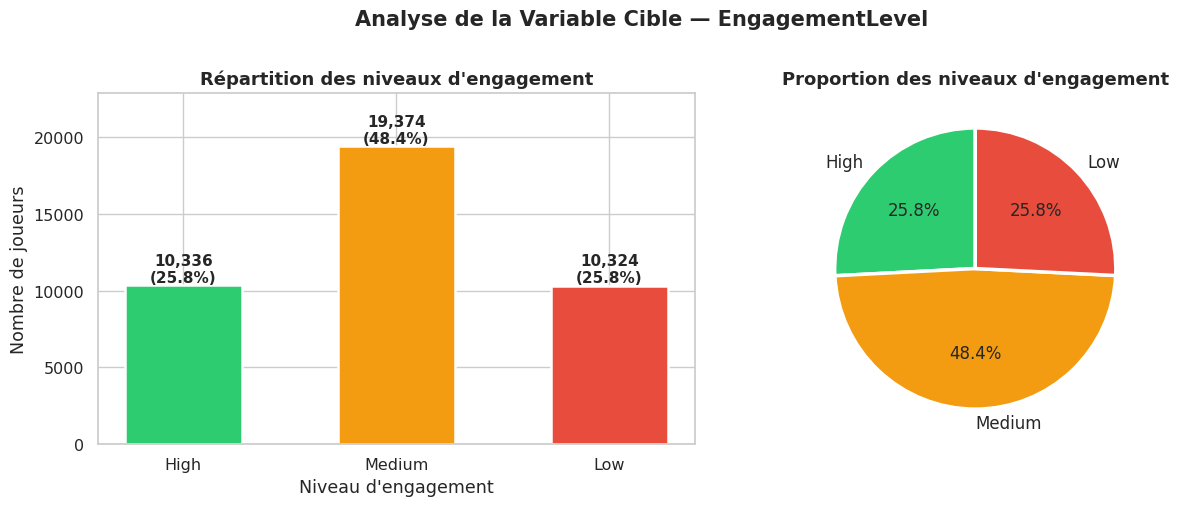

💾 Figure 1 sauvegardée : figures/fig_01_distribution_cible.png


In [ ]:
# Création d'une figure contenant deux graphiques côte à côte
# (diagramme en barres et diagramme circulaire)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
# Définition des couleurs associées à chaque niveau d'engagement
couleurs = {'High': '#2ecc71', 'Medium': '#f39c12', 'Low': '#e74c3c'}
# Ordre d'affichage des catégories
ordre = ['High', 'Medium', 'Low']
# Récupération du nombre d'observations pour chaque catégorie
vals  = [vc.get(o, 0) for o in ordre]
# Liste des couleurs dans le même ordre
clrs  = [couleurs[o] for o in ordre]

# Diagramme en barres
# Création du graphique en barres
barres = axes[0].bar(ordre, vals, color=clrs, edgecolor='white', linewidth=1.8, width=0.55)
# Personnalisation du graphique
axes[0].set_title("Répartition des niveaux d'engagement")
axes[0].set_xlabel("Niveau d'engagement")
axes[0].set_ylabel("Nombre de joueurs")
# Ajout d'un espace au-dessus des barres pour les annotations
axes[0].set_ylim(0, max(vals) * 1.18)
# Affichage du nombre de joueurs et du pourcentage sur chaque barre
for barre, val in zip(barres, vals):
    axes[0].text(
        barre.get_x() + barre.get_width() / 2,
        barre.get_height() + 200,
        f"{val:,}\n({val/len(df)*100:.1f}%)",
        ha='center', fontweight='bold', fontsize=11
    )

# Diagramme circulaire
# Création d'un graphique en secteurs (camembert)
axes[1].pie(
    vals, labels=ordre, colors=clrs,
    autopct='%1.1f%%', # Affichage des pourcentages
    startangle=90,  # Rotation pour une meilleure présentation
    wedgeprops={'edgecolor': 'white', 'linewidth': 2.5},
    textprops={'fontsize': 12}
)
# Titre du diagramme circulaire
axes[1].set_title("Proportion des niveaux d'engagement")
# ───────────────── Mise en forme finale ─────────────────

# Titre général de la figure
plt.suptitle("Analyse de la Variable Cible — EngagementLevel", fontsize=15, fontweight='bold', y=1.01)
# Ajustement automatique des espacements
plt.tight_layout()
# Sauvegarde de la figure en haute résolution
plt.savefig('figures/fig_01_distribution_cible.png', dpi=300, bbox_inches='tight')
# Affichage de la figure
plt.show()
# Message de confirmation
print("💾 Figure 1 sauvegardée : figures/fig_01_distribution_cible.png")

In [ ]:
# 2.6 Distribution des variables numériques par niveau d'engagement

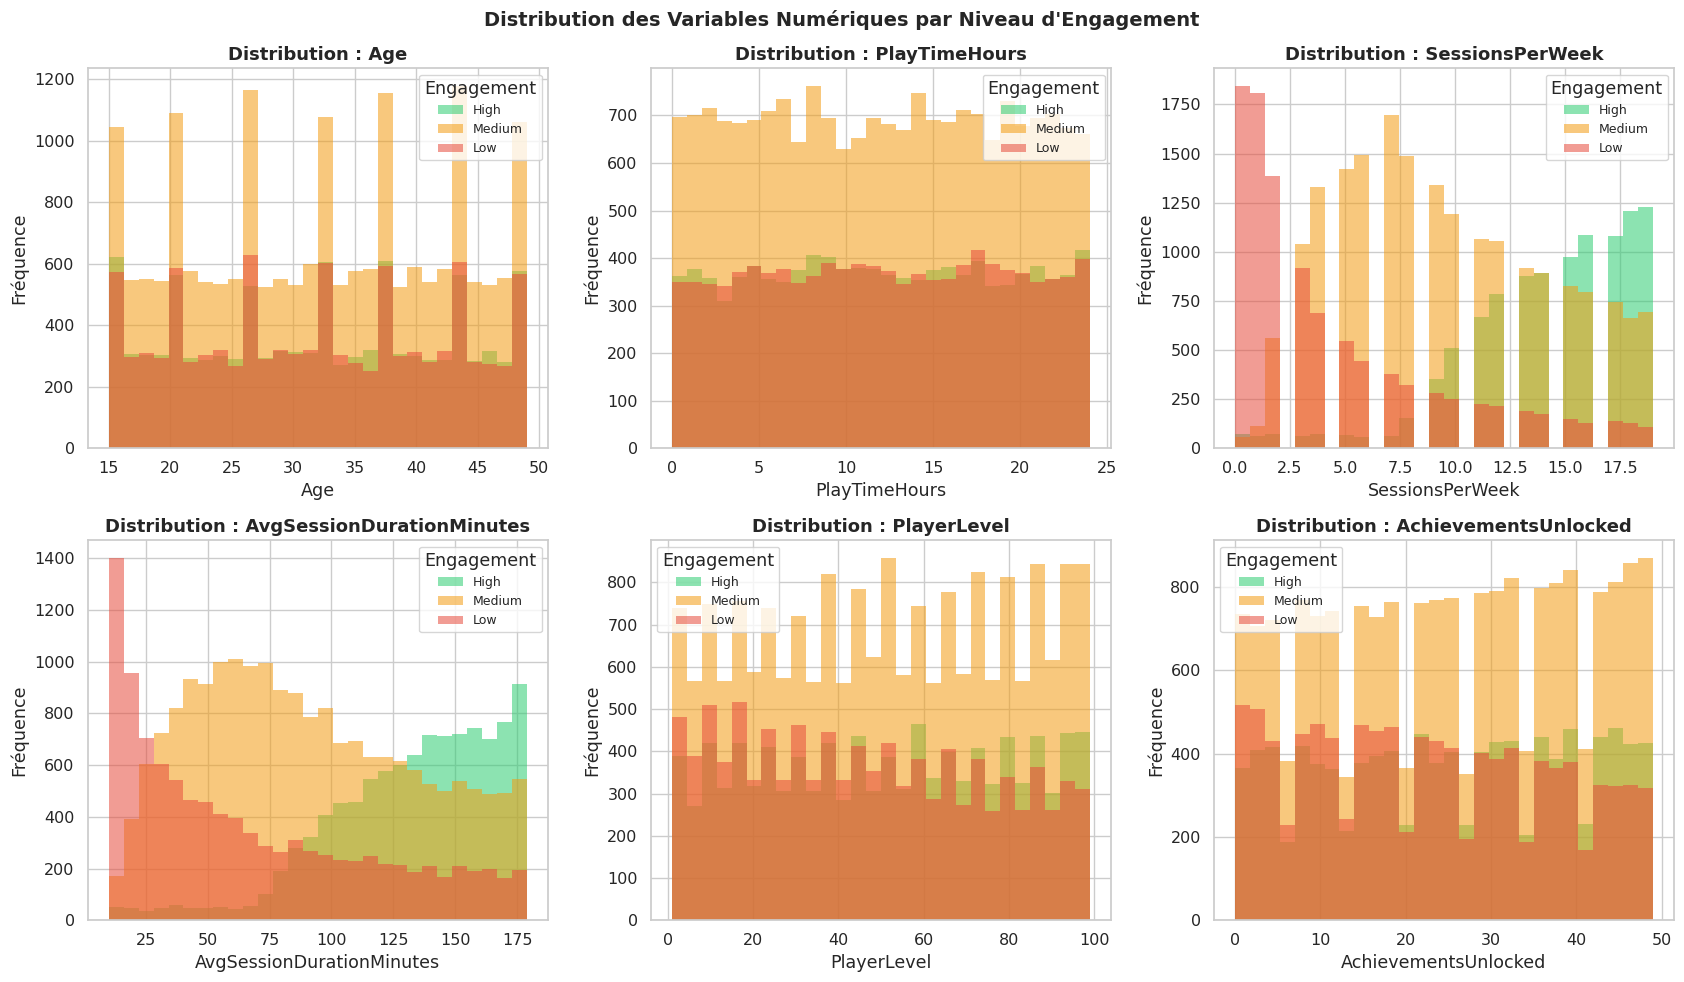

💾 Figure 2 sauvegardée : figures/fig_02_histogrammes_numeriques.png


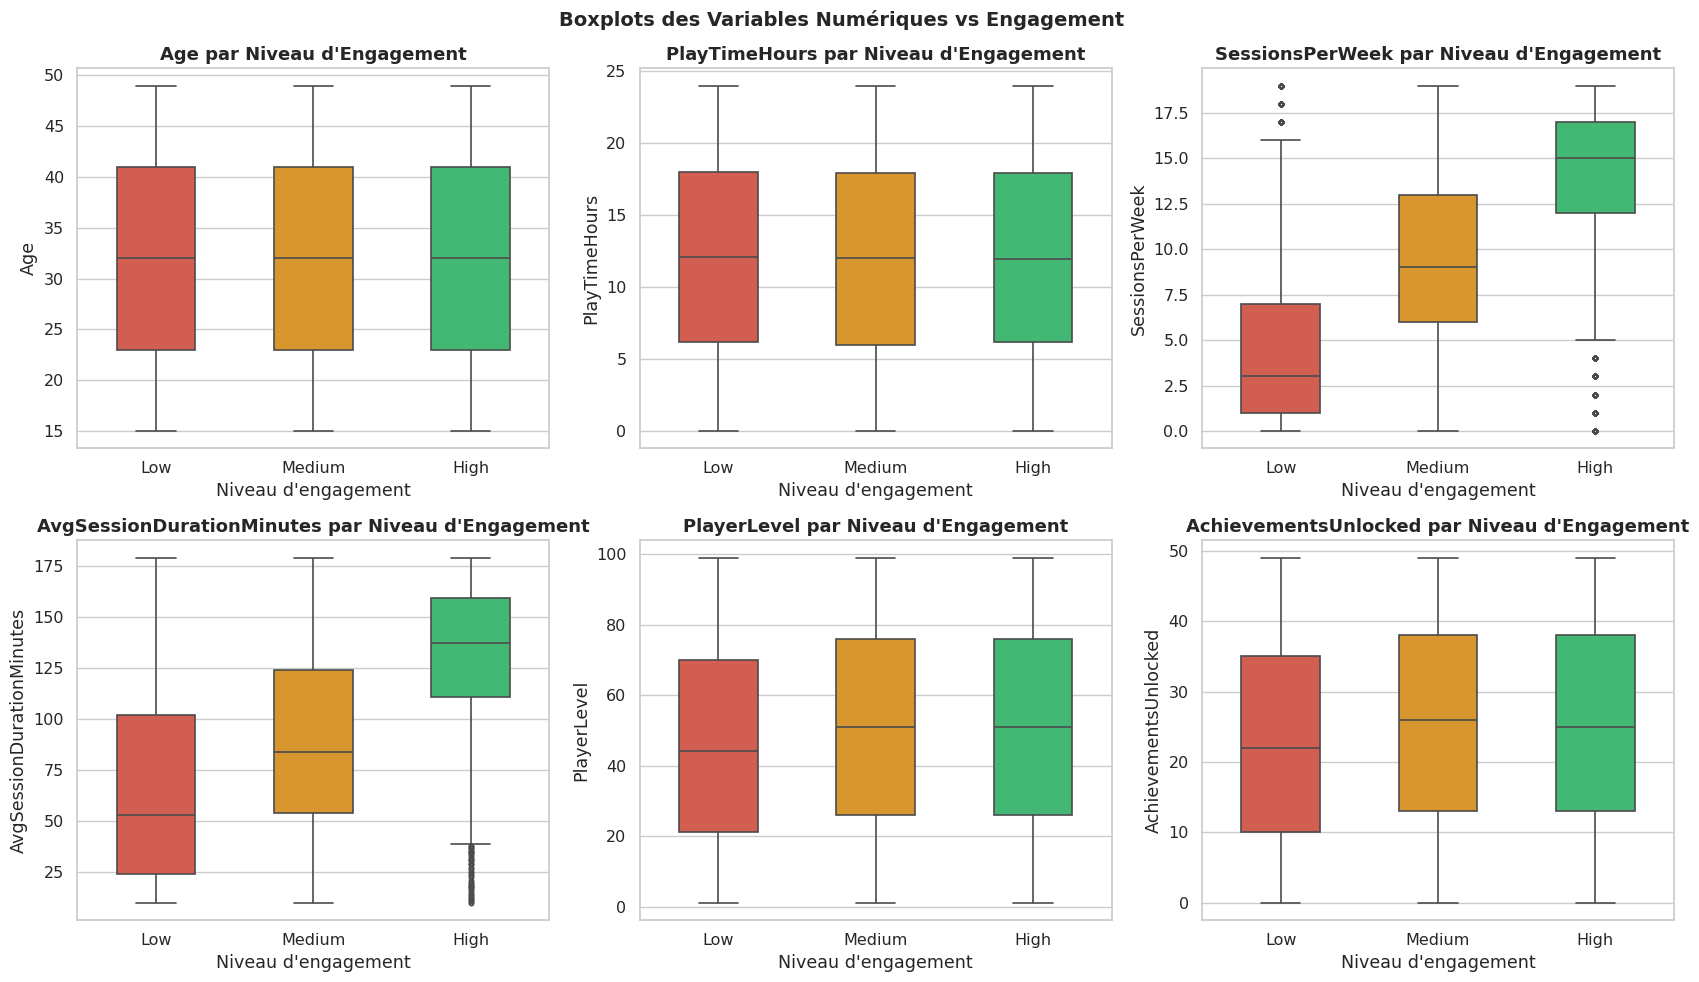

💾 Figure 3 sauvegardée : figures/fig_03_boxplots.png


In [ ]:
# On visualise comment chaque variable numérique se distribue selon le niveau
# d'engagement du joueur. Cela nous aide à identifier les features discriminantes.

# FIGURE 2 — Histogrammes des variables numériques
# Création d'une figure composée de 6 sous-graphiques (2 lignes × 3 colonnes)
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
# Transformation de la matrice d'axes en vecteur pour faciliter l'itération
axes = axes.flatten()
# Couleurs associées à chaque niveau d'engagement
palette_hist = {'High': '#2ecc71', 'Medium': '#f39c12', 'Low': '#e74c3c'}
# Parcours de chaque variable numérique
for i, col in enumerate(cols_num):
  # Pour chaque niveau d'engagement,
    # on trace un histogramme superposé
    for niveau, couleur in palette_hist.items():
      # Sélection des joueurs appartenant au niveau d'engagement courant
        sous_ensemble = df[df['EngagementLevel'] == niveau][col]
         # Création de l'histogramme
        axes[i].hist(sous_ensemble, bins=28, alpha=0.55, color=couleur,
                     label=niveau, edgecolor='none')
        # Personnalisation du graphique
    axes[i].set_title(f"Distribution : {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Fréquence")
    axes[i].legend(title="Engagement", fontsize=9)
# Titre général de la figure
plt.suptitle("Distribution des Variables Numériques par Niveau d'Engagement",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/fig_02_histogrammes_numeriques.png', dpi=300, bbox_inches='tight')
plt.show()
print("💾 Figure 2 sauvegardée : figures/fig_02_histogrammes_numeriques.png")

# FIGURE 3 — Boxplots : variables numériques vs EngagementLevel
# Les boxplots permettent de voir la médiane, les quartiles et les outliers
# pour chaque groupe de joueurs.
# Création d'une figure composée de 6 sous-graphiques
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.flatten()
# Parcours de chaque variable numérique
for i, col in enumerate(cols_num):
   # Création du boxplot selon le niveau d'engagement
    sns.boxplot(
        data=df, x='EngagementLevel', y=col,
        order=['Low', 'Medium', 'High'],
        palette={'Low': '#e74c3c', 'Medium': '#f39c12', 'High': '#2ecc71'},
        ax=axes[i], width=0.5, linewidth=1.2,
         # Personnalisation des points aberrants
        flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.4}
    )
     # Personnalisation des axes
    axes[i].set_title(f"{col} par Niveau d'Engagement")
    axes[i].set_xlabel("Niveau d'engagement")
    axes[i].set_ylabel(col)
# Titre général de la figure
plt.suptitle("Boxplots des Variables Numériques vs Engagement",
             fontsize=14, fontweight='bold')
# Ajustement automatique de l'espacement
plt.tight_layout()
plt.savefig('figures/fig_03_boxplots.png', dpi=300, bbox_inches='tight')
plt.show()
print("💾 Figure 3 sauvegardée : figures/fig_03_boxplots.png")

In [ ]:
# 2.7 Analyse des variables catégorielles


📊 Analyse des variables catégorielles :

  Tableau de contingence — Gender vs EngagementLevel :
EngagementLevel  High   Low  Medium
Gender                             
Female           26.1  25.6    48.3
Male             25.6  25.9    48.5

  Tableau de contingence — Location vs EngagementLevel :
EngagementLevel  High   Low  Medium
Location                           
Asia             26.3  25.4    48.3
Europe           25.6  26.2    48.3
Other            25.7  26.3    48.0
USA              25.8  25.5    48.7

  Tableau de contingence — GameGenre vs EngagementLevel :
EngagementLevel  High   Low  Medium
GameGenre                          
Action           25.7  25.6    48.7
RPG              25.0  26.4    48.6
Simulation       26.4  26.2    47.5
Sports           25.9  25.8    48.3
Strategy         26.2  25.0    48.8

  Tableau de contingence — GameDifficulty vs EngagementLevel :
EngagementLevel  High   Low  Medium
GameDifficulty                     
Easy             25.6  26.0    48.3
Ha

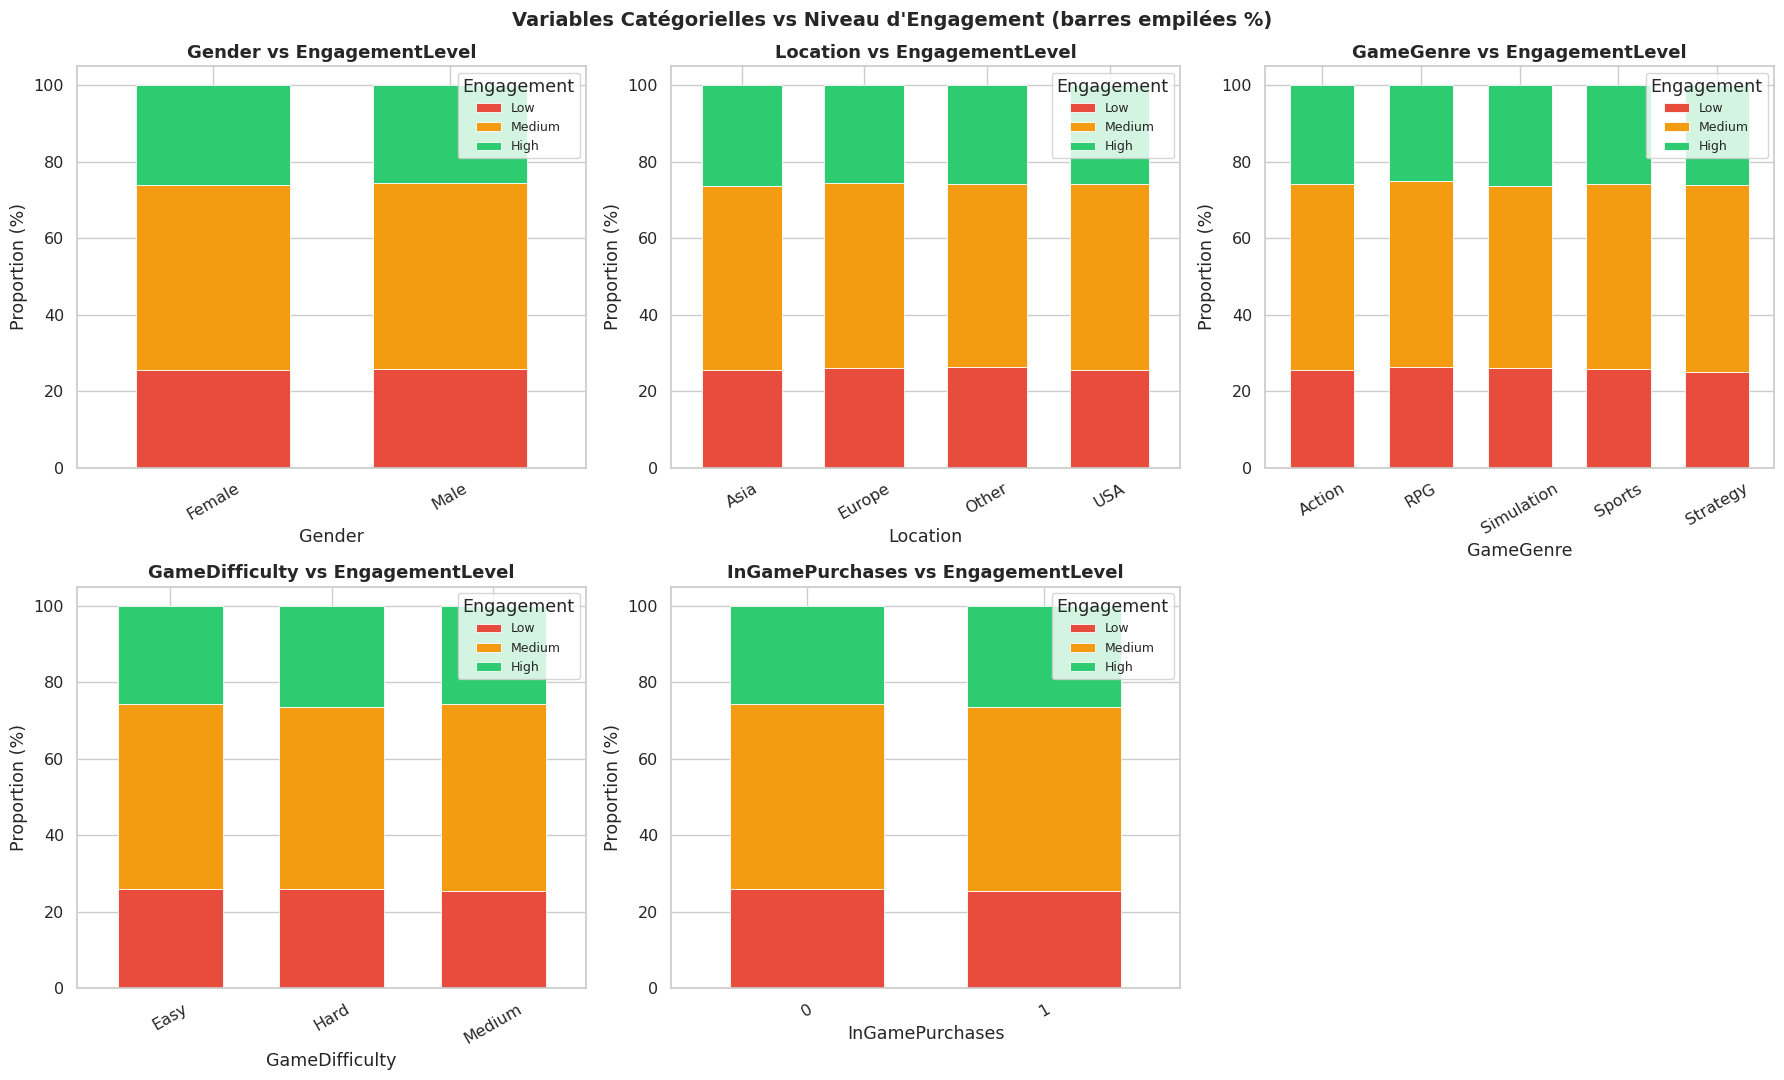

💾 Figure 4 sauvegardée : figures/fig_04_variables_categorielles.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pour chaque variable catégorielle, on calcule le tableau de contingence
# normalisé (en %) pour voir la répartition du churn par modalité.
# Analyse des variables catégorielles en fonction du niveau d'engagement
# L'objectif est d'étudier comment les différentes modalités
# (genre, localisation, difficulté, etc.) sont réparties
# selon les niveaux d'engagement des joueurs.

print("\n📊 Analyse des variables catégorielles :")
# Liste des variables catégorielles à analyser
vars_cat = ['Gender', 'Location', 'GameGenre', 'GameDifficulty', 'InGamePurchases']
# Parcours de chaque variable catégorielle
for col in vars_cat:
    print(f"\n  Tableau de contingence — {col} vs EngagementLevel :")
    # Construction d'un tableau de contingence normalisé
    # normalize='index' calcule les proportions ligne par ligne
    ct = pd.crosstab(df[col], df['EngagementLevel'], normalize='index').round(3) * 100
    # Affichage des pourcentages
    print(ct.to_string())

# FIGURE 4 — Barres empilées : catégorielles vs EngagementLevel
# Création d'une figure composée de 6 sous-graphiques
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
# Conversion du tableau d'axes en vecteur
axes = axes.flatten()
# Création d'un graphique pour chaque variable catégorielle
for i, col in enumerate(vars_cat):
   # Tableau de contingence normalisé en pourcentage
    ct = pd.crosstab(df[col], df['EngagementLevel'], normalize='index') * 100
     # Ordre cohérent des catégories d'engagement
    ct_ordered = ct[['Low', 'Medium', 'High']]
     # Création d'un diagramme en barres empilées
    ct_ordered.plot(
        kind='bar', stacked=True, ax=axes[i],
         # Couleurs associées aux niveaux d'engagement
        color=[
            '#e74c3c', # Low
            '#f39c12', # Medium
            '#2ecc71'  # High
        ],
        edgecolor='white', linewidth=0.6, width=0.65
         # Personnalisation du graphique
    )
    axes[i].set_title(f"{col} vs EngagementLevel")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Proportion (%)")
    # Rotation des étiquettes pour améliorer la lisibilité
    axes[i].tick_params(axis='x', rotation=30)
     # Affichage de la légende
    axes[i].legend(title='Engagement', loc='upper right', fontsize=9)

# Masquer le 6e sous-graphique (non utilisé)
# (5 variables seulement pour une grille de 6 emplacements)
axes[-1].set_visible(False)
# Titre général de la figure
plt.suptitle("Variables Catégorielles vs Niveau d'Engagement (barres empilées %)",
             fontsize=14, fontweight='bold')
# Ajustement automatique de la mise en page
plt.tight_layout()
# Sauvegarde de la figure
plt.savefig('figures/fig_04_variables_categorielles.png', dpi=300, bbox_inches='tight')
plt.show()
print("💾 Figure 4 sauvegardée : figures/fig_04_variables_categorielles.png")

In [ ]:
# 2.8 Matrice de corrélation


🔗 Corrélations avec la variable Churned :
SessionsPerWeek             -0.505379
AvgSessionDurationMinutes   -0.335694
AchievementsUnlocked        -0.076181
PlayerLevel                 -0.073287
Age                         -0.005611
PlayTimeHours                0.006867
Churned                      1.000000

  → SessionsPerWeek et AvgSessionDurationMinutes sont
    les variables les plus corrélées avec le churn (négatif).


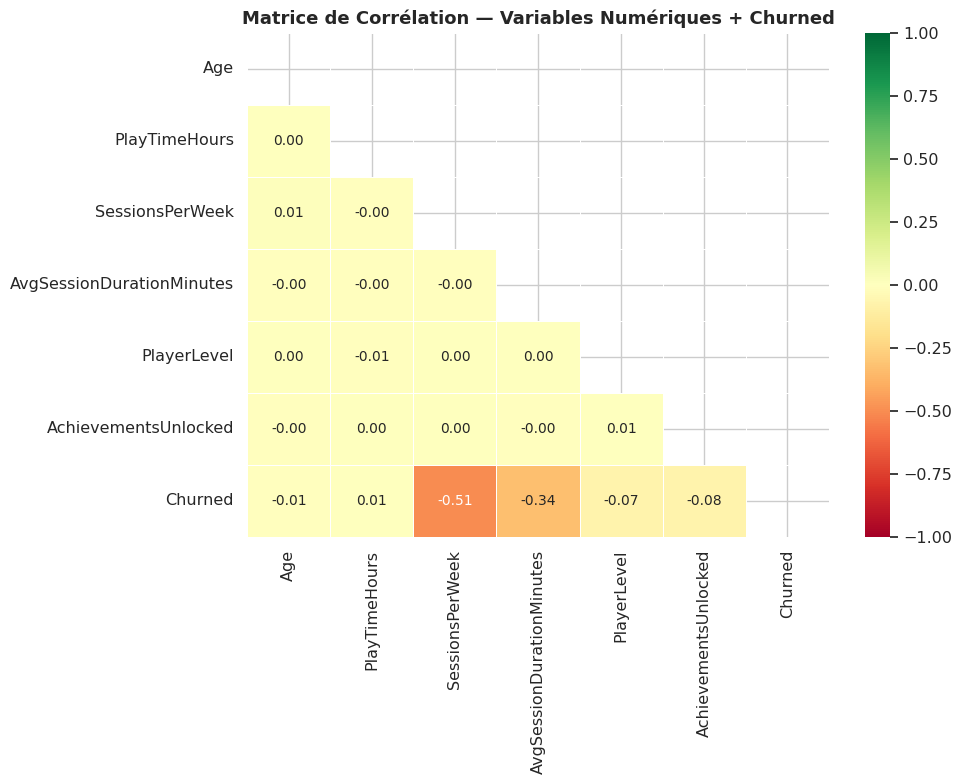

💾 Figure 5 sauvegardée : figures/fig_05_matrice_correlation.png


In [ ]:
# La matrice de corrélation (Pearson) mesure les relations linéaires entre
# variables numériques. Valeurs proches de ±1 = forte corrélation.
# On utilise un masque triangulaire pour éviter la redondance.
# Analyse des corrélations entre les variables numériques et le churn
# La corrélation de Pearson mesure l'intensité et le sens de la relation
# linéaire entre deux variables :
# - proche de +1 : forte corrélation positive
# - proche de -1 : forte corrélation négative
# - proche de 0 : absence de relation linéaire significative

# Pour étudier le churn, la variable cible EngagementLevel
# est temporairement transformée en variable binaire :
# 1 = joueur à risque de churn (Low)
# 0 = joueur engagé (Medium ou High)

# On encode temporairement la cible pour voir ses corrélations
# Création d'un DataFrame contenant uniquement les variables numériques
df_corr = df[cols_num].copy()
# Encodage binaire de la variable cible
df_corr['Churned'] = (df['EngagementLevel'] == 'Low').astype(int)
# Calcul de la matrice de corrélation
corr = df_corr.corr()
# Affichage des corrélations avec la variable Churned
print("\n🔗 Corrélations avec la variable Churned :")
print(corr['Churned'].sort_values().to_string())
# Interprétation des résultats
print("\n  → SessionsPerWeek et AvgSessionDurationMinutes sont")
print("    les variables les plus corrélées avec le churn (négatif).")

# FIGURE 5 — Matrice de corrélation (heatmap triangulaire)
# Création de la figure
fig, ax = plt.subplots(figsize=(10, 8))
# Construction d'un masque triangulaire supérieur
# afin d'éviter d'afficher deux fois les mêmes corrélations
masque = np.triu(np.ones_like(corr, dtype=bool))  # Triangle supérieur masqué
# Création de la heatmap
sns.heatmap(
   # Application du masque triangulaire
    corr, mask=masque,
    # Affichage des coefficients de corrélation
    annot=True, fmt='.2f',
    # Palette de couleurs :
    # rouge = corrélation négative
    # jaune = corrélation faible
    # vert = corrélation positive
    cmap='RdYlGn', center=0, vmin=-1, vmax=1,
    linewidths=0.5, linecolor='white',
    annot_kws={'size': 10},
    ax=ax
)
# Titre du graphique
ax.set_title("Matrice de Corrélation — Variables Numériques + Churned",
             fontsize=13, fontweight='bold')
# Ajustement automatique de la mise en page
plt.tight_layout()
# Sauvegarde de la figure
plt.savefig('figures/fig_05_matrice_correlation.png', dpi=300, bbox_inches='tight')
# Affichage de la figure
plt.show()
# Message de confirmation
print("💾 Figure 5 sauvegardée : figures/fig_05_matrice_correlation.png")

## 5. Modélisation

In [ ]:
# SECTION 3 — PRÉTRAITEMENT DES DONNÉES & FEATURE ENGINEERING

## 6. Évaluation & Comparaison des Modèles

In [ ]:
print("\n" + "="*60)
print("  SECTION 3 — PRÉTRAITEMENT & FEATURE ENGINEERING")
print("="*60)


  SECTION 3 — PRÉTRAITEMENT & FEATURE ENGINEERING


In [ ]:
# 3.1 Copie de travail et suppression de la colonne identifiant

In [ ]:
# Dans cette étape de prétraitement, nous avons supprimé la variable PlayerID car il s'agit d'un identifiant unique sans valeur prédictive.
# Cette suppression permet d'éviter l'introduction de bruit dans le modèle et de conserver uniquement les variables utiles à l'apprentissage

df_prep = df.copy() # On crée une copie du DataFrame original df pour éviter de modifier les données de départ.
df_prep.drop(columns=['PlayerID'], inplace=True) #On supprime la colonne PlayerID.
print(f"\n✅ Colonne 'PlayerID' supprimée — {df_prep.shape[1]} variables restantes") #Affiche un message confirmant la suppression et indique le nombre de variables restantes.


✅ Colonne 'PlayerID' supprimée — 12 variables restantes


In [ ]:
# 3.2 Création de la variable cible binaire : Churned

In [ ]:
#Dans cette étape, nous avons créé la variable cible binaire Churned à partir du niveau d'engagement des joueurs.
#Les joueurs ayant un engagement faible (Low) sont considérés comme churnés (1), tandis que les autres sont considérés comme actifs (0).

df_prep['Churned'] = (df_prep['EngagementLevel'] == 'Low').astype(int)

print("\n🎯 Variable cible binaire 'Churned' créée :")
churn_dist = df_prep['Churned'].value_counts()
print(f"   Churned = 0 (Non churné) : {churn_dist[0]:,} joueurs ({churn_dist[0]/len(df_prep)*100:.1f}%)")
print(f"   Churned = 1 (Churné)     : {churn_dist[1]:,} joueurs ({churn_dist[1]/len(df_prep)*100:.1f}%)")
print(f"\n   → Déséquilibre des classes détecté : ratio ~3:1")
print(f"   → SMOTE sera appliqué pour équilibrer l'entraînement")

#L'analyse de la distribution a révélé un déséquilibre des classes d'environ 3:1
#ce qui a motivé l'utilisation de la technique SMOTE pour équilibrer les données avant l'entraînement du modèle.


🎯 Variable cible binaire 'Churned' créée :
   Churned = 0 (Non churné) : 29,710 joueurs (74.2%)
   Churned = 1 (Churné)     : 10,324 joueurs (25.8%)

   → Déséquilibre des classes détecté : ratio ~3:1
   → SMOTE sera appliqué pour équilibrer l'entraînement


In [ ]:
# 3.3 Feature Engineering — Création de nouvelles variables

In [ ]:
# Le Feature Engineering consiste à créer de nouvelles variables plus informatives à partir des données existantes
# afin d’aider le modèle à mieux comprendre le comportement des joueurs et améliorer la prédiction du churn.

# ── Feature 1 : WeeklyPlayHours ──────────────────────────────────────────────
# Heures de jeu totales par semaine = PlayTimeHours × SessionsPerWeek
# Un joueur qui joue peu d'heures ET peu souvent sera plus à risque de churn.
# Cette feature capture l'investissement temporel hebdomadaire global.
df_prep['WeeklyPlayHours'] = df_prep['PlayTimeHours'] * df_prep['SessionsPerWeek']

# ── Feature 2 : AchievementPerLevel ──────────────────────────────────────────
# Ratio succès débloqués / niveau atteint
# Un joueur de niveau 80 avec seulement 5 succès est probablement moins engagé
# qu'un joueur de niveau 20 avec 40 succès. Ce ratio mesure l'engagement
# relatif à la progression dans le jeu.
df_prep['AchievementPerLevel'] = (
    df_prep['AchievementsUnlocked'] / (df_prep['PlayerLevel'] + 1)  # +1 évite la division par zéro
)

# ── Feature 3 : EngagementScore ──────────────────────────────────────────────
#On combine deux informations :
#SessionsPerWeek → fréquence de jeu (combien de fois par semaine)
#AvgSessionDurationMinutes → durée moyenne d’une session
#On multiplie les deux pour obtenir le temps total de jeu hebdomadaire, puis on divise par 60 pour convertir en heures.
df_prep['EngagementScore'] = (
    df_prep['SessionsPerWeek'] * df_prep['AvgSessionDurationMinutes'] / 60.0
)

print("\n✅ Nouvelles features créées par Feature Engineering :")
print("   • WeeklyPlayHours      : heures de jeu totales par semaine")
print("     Formule : PlayTimeHours × SessionsPerWeek")
print(f"     Plage   : {df_prep['WeeklyPlayHours'].min():.1f} – {df_prep['WeeklyPlayHours'].max():.1f} h/semaine\n")
print("   • AchievementPerLevel  : ratio succès / niveau du joueur")
print("     Formule : AchievementsUnlocked / (PlayerLevel + 1)")
print(f"     Plage   : {df_prep['AchievementPerLevel'].min():.3f} – {df_prep['AchievementPerLevel'].max():.3f}\n")
print("   • EngagementScore      : score d'engagement global")
print("     Formule : SessionsPerWeek × AvgSessionDurationMinutes / 60")
print(f"     Plage   : {df_prep['EngagementScore'].min():.2f} – {df_prep['EngagementScore'].max():.2f} h\n")

#WeeklyPlayHours
#0h ➜ joueur inactif
#455h ➜ joueur très intensif (très engagé)

#AchievementPerLevel
#proche de 0 ➜ peu de succès par rapport au niveau (faible engagement)
#élevé (jusqu’à 24.5) ➜ joueur très actif et performant

#EngagementScore
#0 ➜ joueur quasi inactif
#56h ➜ joueur très actif (beaucoup de sessions longues)


✅ Nouvelles features créées par Feature Engineering :
   • WeeklyPlayHours      : heures de jeu totales par semaine
     Formule : PlayTimeHours × SessionsPerWeek
     Plage   : 0.0 – 455.9 h/semaine

   • AchievementPerLevel  : ratio succès / niveau du joueur
     Formule : AchievementsUnlocked / (PlayerLevel + 1)
     Plage   : 0.000 – 24.500

   • EngagementScore      : score d'engagement global
     Formule : SessionsPerWeek × AvgSessionDurationMinutes / 60
     Plage   : 0.00 – 56.68 h



In [ ]:
# 3.4 Encodage des variables catégorielles

In [ ]:
# Ce code fait de l’encodage des variables catégorielles pour les transformer en valeurs numériques,
#car les modèles de Machine Learning ne comprennent pas le texte.

print("🔄 Encodage des variables catégorielles :")
encodeur = LabelEncoder()
vars_cat_encode = ['Gender', 'Location', 'GameGenre', 'GameDifficulty']

for col in vars_cat_encode:
    df_prep[col + '_enc'] = encodeur.fit_transform(df_prep[col])
    mapping = dict(enumerate(encodeur.classes_))
    print(f"   {col:20s} → {col}_enc   Mapping : {mapping}")

🔄 Encodage des variables catégorielles :
   Gender               → Gender_enc   Mapping : {0: 'Female', 1: 'Male'}
   Location             → Location_enc   Mapping : {0: 'Asia', 1: 'Europe', 2: 'Other', 3: 'USA'}
   GameGenre            → GameGenre_enc   Mapping : {0: 'Action', 1: 'RPG', 2: 'Simulation', 3: 'Sports', 4: 'Strategy'}
   GameDifficulty       → GameDifficulty_enc   Mapping : {0: 'Easy', 1: 'Hard', 2: 'Medium'}


In [ ]:
# 3.5 Sélection des features et de la variable cible

In [ ]:
# On sélectionne les 14 features qui serviront à l'entraînement des modèles.
# On exclut : PlayerID (supprimé)
features = [
    # ── Variables numériques originales ──────────────────────────────────
    'Age',                       # Âge du joueur
    'PlayTimeHours',             # Heures de jeu par session
    'InGamePurchases',           # Achats in-game (binaire 0/1)
    'SessionsPerWeek',           # Sessions par semaine ← forte corrélation churn
    'AvgSessionDurationMinutes', # Durée moyenne session ← forte corrélation churn
    'PlayerLevel',               # Niveau du joueur
    'AchievementsUnlocked',      # Succès débloqués
    # ── Variables catégorielles encodées ─────────────────────────────────
    'Gender_enc',                # Genre (Male=1, Female=0)
    'Location_enc',              # Région géographique (encodée)
    'GameGenre_enc',             # Genre du jeu (encodé)
    'GameDifficulty_enc',        # Difficulté (Easy=0, Hard=1, Medium=2)
    # ── Nouvelles features (Feature Engineering) ─────────────────────────
    'WeeklyPlayHours',           # Heures jeu total / semaine
    'AchievementPerLevel',       # Ratio succès / niveau
    'EngagementScore'            # Score d'engagement global
]
##on va construit la matrice finale d’apprentissage X et la variable cible y, en combinant variables originales,
#encodées et nouvelles features pour entraîner un modèle de prédiction du churn.
X = df_prep[features]   # Matrice des features (40 034 × 14)
y = df_prep['Churned']  # Vecteur cible (0 ou 1)

print(f"\n✅ Features sélectionnées : {len(features)}")
print(f"   Matrice X : {X.shape[0]:,} lignes × {X.shape[1]} colonnes")#40,034 lignes le nombre de joueurs dans le dataset et 14 colonnes le nombre de features utilisées
print(f"   Vecteur y : {y.shape[0]:,} éléments (0 ou 1)")#40,034 éléments = une par joueur et chaque valeur est : 0 → joueur actif ou 1 → joueur à risque d’abandon


✅ Features sélectionnées : 14
   Matrice X : 40,034 lignes × 14 colonnes
   Vecteur y : 40,034 éléments (0 ou 1)


In [ ]:
# 3.6 Division des données : Train / Test (80% / 20%)

In [ ]:
# On divise les données en deux ensembles :
#   Train (80%) : utilisé pour entraîner les modèles
#   Test  (20%) : utilisé pour évaluer les performances sur des données inconnues
# random_state=42 assure la reproductibilité des résultats.

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y          # Préserve la proportion des classes dans chaque split
)

print(f"\n📂 Division Train/Test :")
print(f"   Train : {X_train.shape[0]:,} échantillons ({X_train.shape[0]/len(X)*100:.0f}%)")#utilisé pour entraîner le modèle
print(f"   Test  : {X_test.shape[0]:,} échantillons ({X_test.shape[0]/len(X)*100:.0f}%)")#utilisé pour tester le modèle sur des données qu’il n’a jamais vues
print(f"   Taux churn Train : {y_train.mean()*100:.1f}%  |  Test : {y_test.mean()*100:.1f}%  ← bien stratifié")#dans le train et test : 25.8% des joueurs sont churnés
#garder la même proportion de classes dans train et test


📂 Division Train/Test :
   Train : 32,027 échantillons (80%)
   Test  : 8,007 échantillons (20%)
   Taux churn Train : 25.8%  |  Test : 25.8%  ← bien stratifié


In [ ]:
# 3.7 Normalisation — StandardScaler

In [ ]:
#Ce code sert à normaliser les données avant d’entraîner un modèle de Régression Logistique,
#afin que toutes les variables soient sur la même échelle.

scaler = StandardScaler() #➡️ Création du normalisateur.
X_train_scale = pd.DataFrame(
    scaler.fit_transform(X_train),   # fit : apprend moyenne et écart-type + transform sur Train : applique la normalisation
    columns=features
)
X_test_scale = pd.DataFrame(
    scaler.transform(X_test),        # transform uniquement sur Test (pas de recalcul)
    columns=features
)

print(f"\n✅ Normalisation StandardScaler appliquée :")
print(f"   Avant normalisation — PlayTimeHours  : min={X_train['PlayTimeHours'].min():.2f}, max={X_train['PlayTimeHours'].max():.2f}")
print(f"   Après normalisation — PlayTimeHours  : min={X_train_scale['PlayTimeHours'].min():.2f}, max={X_train_scale['PlayTimeHours'].max():.2f}")
#Avant normalisation min = 0 et max = 24 = Ça veut dire que les joueurs jouent entre 0h et 24h
#Après normalisation (StandardScaler) min = -1.73 joueur très peu actif par rapport aux autres et 0 ➜ joueur moyen et +1.74 ➜ joueur très actif

#Pourquoi on obtient des valeurs négatives ?
#Parce que StandardScaler fait : xscaled = x-moyenne / ecarttype
#si un joueur joue moins que la moyenne ➜ valeur négative
#si un joueur joue plus que la moyenne ➜ valeur positive


✅ Normalisation StandardScaler appliquée :
   Avant normalisation — PlayTimeHours  : min=0.00, max=24.00
   Après normalisation — PlayTimeHours  : min=-1.73, max=1.74


## 7. Résumé Final

In [ ]:
# SECTION 4 — GESTION DU DÉSÉQUILIBRE — SMOTE

In [ ]:
print("\n" + "="*60)
print("  SECTION 4 — GESTION DU DÉSÉQUILIBRE (SMOTE)")
print("="*60)


  SECTION 4 — GESTION DU DÉSÉQUILIBRE (SMOTE)



⚖️  Distribution AVANT SMOTE (sur Train) :
   Non churné (0) : 23,768 (74.2%)
   Churné     (1) : 8,259 (25.8%)

⚖️  Distribution APRÈS SMOTE (sur Train) :
   Non churné (0) : 23,768 (50.0%)
   Churné     (1) : 23,768 (50.0%)
   → 15,509 exemples synthétiques générés


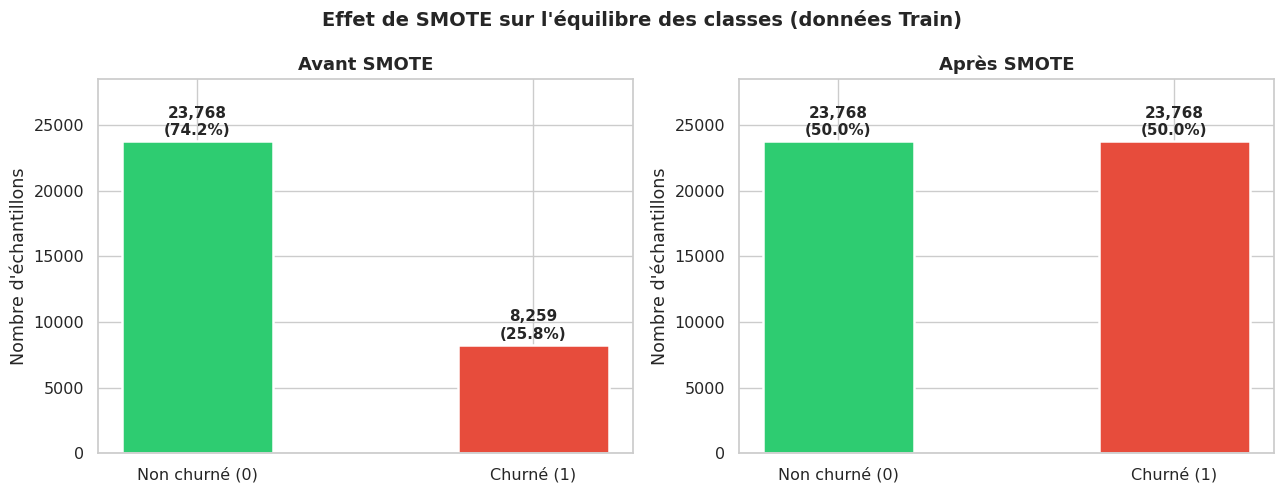

💾 Figure 6 sauvegardée : figures/fig_06_smote_equilibrage.png


In [ ]:
# Le déséquilibre des classes (74% non-churné vs 26% churné) pose un problème :
# un modèle peut atteindre 74% d'accuracy en prédisant toujours "non-churné",
# sans jamais détecter un seul cas de churn réel.
#
# SMOTE (Synthetic Minority Over-sampling Technique) résout ce problème en
# créant de nouveaux exemples synthétiques de la classe minoritaire (Churned=1),
# en interpolant entre des exemples existants dans l'espace des features.
#
# ⚠️  SMOTE est appliqué UNIQUEMENT sur les données d'entraînement.
#     Les données de test restent intactes pour une évaluation réaliste.

avant_counts = y_train.value_counts()
print(f"\n⚖️  Distribution AVANT SMOTE (sur Train) :")
print(f"   Non churné (0) : {avant_counts[0]:,} ({avant_counts[0]/len(y_train)*100:.1f}%)")
print(f"   Churné     (1) : {avant_counts[1]:,} ({avant_counts[1]/len(y_train)*100:.1f}%)")

smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train_scale, y_train)

apres_counts = pd.Series(y_train_sm).value_counts()
print(f"\n⚖️  Distribution APRÈS SMOTE (sur Train) :")
print(f"   Non churné (0) : {apres_counts[0]:,} ({apres_counts[0]/len(y_train_sm)*100:.1f}%)")
print(f"   Churné     (1) : {apres_counts[1]:,} ({apres_counts[1]/len(y_train_sm)*100:.1f}%)")
print(f"   → {apres_counts[1] - avant_counts[1]:,} exemples synthétiques générés")

# FIGURE 6 — Comparaison avant/après SMOTE
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, counts, titre in zip(
    axes,
    [avant_counts, apres_counts],
    ['Avant SMOTE', 'Après SMOTE']
):
    ax.bar(
        ['Non churné (0)', 'Churné (1)'],
        [counts[0], counts[1]],
        color=['#2ecc71', '#e74c3c'],
        edgecolor='white', linewidth=1.8, width=0.45
    )
    ax.set_title(titre, fontsize=13)
    ax.set_ylabel("Nombre d'échantillons")
    ax.set_ylim(0, max(counts[0], counts[1]) * 1.2)
    for i, v in enumerate([counts[0], counts[1]]):
        total = len(y_train) if titre == 'Avant SMOTE' else len(y_train_sm)
        ax.text(i, v + max(counts[0], counts[1]) * 0.02,
                f"{v:,}\n({v/total*100:.1f}%)",
                ha='center', fontweight='bold', fontsize=11)

plt.suptitle("Effet de SMOTE sur l'équilibre des classes (données Train)",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/fig_06_smote_equilibrage.png', dpi=300, bbox_inches='tight')
plt.show()
print("💾 Figure 6 sauvegardée : figures/fig_06_smote_equilibrage.png")

## Modélisation

In [ ]:
# SECTION 5 — MODÉLISATION

In [ ]:
print("\n" + "="*60)
print("  SECTION 5 — MODÉLISATION")
print("="*60)


  SECTION 5 — MODÉLISATION


In [ ]:
# On entraîne 3 modèles de classification sur les données équilibrées (SMOTE).
# Chaque modèle adopte une approche différente pour capturer les patterns :
#
#  1. Régression Logistique : modèle linéaire de référence (baseline)
#     → Interprétable, rapide, donne les probabilités de churn
#
#  2. Random Forest          : ensemble de 200 arbres de décision (bagging)
#     → Robuste au bruit, capture les non-linéarités, fournit l'importance
#       des features. Chaque arbre vote, la majorité l'emporte.
#
#  3. XGBoost               : gradient boosting optimisé (boosting)
#     → Apprend séquentiellement : chaque modèle corrige les erreurs du
#       précédent. Très performant sur des données tabulaires structurées.

In [ ]:
modeles = {
    # ── Régression Logistique ─────────────────────────────────────────────────
    # max_iter=1000  : assure la convergence sur ce dataset (40k lignes)
    # C=1.0          : régularisation L2 par défaut (inverse de la force de régul.)
    # random_state   : reproductibilité
    'Régression Logistique': LogisticRegression(
        max_iter=1000,
        C=1.0,
        random_state=42
    ),

    # ── Random Forest ─────────────────────────────────────────────────────────
    # n_estimators=200 : 200 arbres de décision (plus = plus robuste)
    # max_depth=10     : profondeur max par arbre (évite l'overfitting)
    # n_jobs=-1        : utilise tous les cœurs CPU disponibles
    # random_state     : reproductibilité
    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=5,
        random_state=42,
        n_jobs=-1
    ),

    # ── XGBoost ───────────────────────────────────────────────────────────────
    # n_estimators=200   : 200 boosting rounds
    # max_depth=6        : profondeur max par arbre (XGBoost recommande 3-10)
    # learning_rate=0.1  : taux d'apprentissage (pas de gradient descent)
    # subsample=0.8      : fraction des données par round (réduction variance)
    # colsample_bytree=0.8 : fraction des features par arbre
    # eval_metric='logloss': métrique de suivi interne
    'XGBoost': XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        random_state=42,
        verbosity=0
    )
}

# Dictionnaire pour stocker les résultats et modèles entraînés
resultats = {}
modeles_entraines = {}

# ── Boucle d'entraînement et d'évaluation ────────────────────────────────────
for nom, modele in modeles.items():
    print(f"\n{'─'*55}")
    print(f"🤖 Entraînement : {nom}")
    print('─'*55)

    # ── Entraînement ─────────────────────────────────────────────────────────
    # On entraîne sur les données augmentées par SMOTE (équilibrées)
    modele.fit(X_train_sm, y_train_sm)

    # ── Prédictions sur les données de TEST (non vues, non équilibrées) ──────
    y_pred      = modele.predict(X_test_scale)
    y_pred_prob = modele.predict_proba(X_test_scale)[:, 1]  # Probabilité d'être churné

    # ── Calcul des métriques ─────────────────────────────────────────────────
    acc  = accuracy_score(y_test, y_pred)
    f1   = f1_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec  = recall_score(y_test, y_pred)
    auc  = roc_auc_score(y_test, y_pred_prob)

    # ── Cross-Validation 5-Fold Stratifiée ───────────────────────────────────
    # On évalue la stabilité du modèle via 5-fold stratified cross-validation.
    # Cela donne une estimation moins biaisée de la performance réelle.
    cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    cv_scores = cross_val_score(
        modele, X_train_sm, y_train_sm,
        cv=cv_strat, scoring='f1', n_jobs=-1
    )

    # ── Sauvegarde des résultats ──────────────────────────────────────────────
    resultats[nom] = {
        'Accuracy' : acc,
        'F1-Score' : f1,
        'Precision': prec,
        'Recall'   : rec,
        'AUC-ROC'  : auc,
        'CV F1 Moyen': cv_scores.mean(),
        'CV F1 Std'  : cv_scores.std()
    }
    modeles_entraines[nom] = {
        'modele': modele,
        'y_pred': y_pred,
        'y_pred_prob': y_pred_prob
    }

    # ── Affichage des métriques ───────────────────────────────────────────────
    print(f"   Accuracy  : {acc:.4f}  ({acc*100:.2f}%)")
    print(f"   F1-Score  : {f1:.4f}  (moyenne harmonique précision/rappel)")
    print(f"   Precision : {prec:.4f} (% de vrais churned parmi les prédits churned)")
    print(f"   Recall    : {rec:.4f}  (% de churned réels détectés)")
    print(f"   AUC-ROC   : {auc:.4f} (capacité de discrimination)")
    print(f"   CV F1     : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}  (stabilité sur 5 folds)")
    print(f"\n📋 Rapport de classification complet :")
    print(classification_report(y_test, y_pred, target_names=['Non Churné', 'Churné']))

print("\n✅ Tous les modèles ont été entraînés et évalués")


───────────────────────────────────────────────────────
🤖 Entraînement : Régression Logistique
───────────────────────────────────────────────────────
   Accuracy  : 0.8444  (84.44%)
   F1-Score  : 0.7476  (moyenne harmonique précision/rappel)
   Precision : 0.6426 (% de vrais churned parmi les prédits churned)
   Recall    : 0.8935  (% de churned réels détectés)
   AUC-ROC   : 0.9248 (capacité de discrimination)
   CV F1     : 0.8741 ± 0.0016  (stabilité sur 5 folds)

📋 Rapport de classification complet :
              precision    recall  f1-score   support

  Non Churné       0.96      0.83      0.89      5942
      Churné       0.64      0.89      0.75      2065

    accuracy                           0.84      8007
   macro avg       0.80      0.86      0.82      8007
weighted avg       0.88      0.84      0.85      8007


───────────────────────────────────────────────────────
🤖 Entraînement : Random Forest
───────────────────────────────────────────────────────
   Accuracy  : 0

## Évaluation & Comparaison Des Modèles

In [ ]:
# SECTION 6 — ÉVALUATION & COMPARAISON DES MODÈLES

In [ ]:
print("\n" + "="*60)
print("  SECTION 6 — ÉVALUATION & COMPARAISON DES MODÈLES")
print("="*60)


  SECTION 6 — ÉVALUATION & COMPARAISON DES MODÈLES


In [ ]:
# 6.1 Tableau comparatif des métriques

In [ ]:
df_resultats = pd.DataFrame(resultats).T.round(4)
df_resultats = df_resultats.sort_values('AUC-ROC', ascending=False)

print("\n📊 Tableau comparatif des modèles :")
print(df_resultats[['Accuracy', 'F1-Score', 'Precision', 'Recall', 'AUC-ROC', 'CV F1 Moyen']].to_string())

meilleur = df_resultats['AUC-ROC'].idxmax()
print(f"\n🏆 Meilleur modèle (AUC-ROC) : {meilleur}")
print(f"   AUC-ROC   : {df_resultats.loc[meilleur, 'AUC-ROC']:.4f}")
print(f"   F1-Score  : {df_resultats.loc[meilleur, 'F1-Score']:.4f}")
print(f"   Accuracy  : {df_resultats.loc[meilleur, 'Accuracy']:.4f}")


📊 Tableau comparatif des modèles :
                       Accuracy  F1-Score  Precision  Recall  AUC-ROC  CV F1 Moyen
XGBoost                  0.9528    0.9070     0.9220  0.8925   0.9391       0.9629
Random Forest            0.9423    0.8890     0.8822  0.8959   0.9379       0.9327
Régression Logistique    0.8444    0.7476     0.6426  0.8935   0.9248       0.8741

🏆 Meilleur modèle (AUC-ROC) : XGBoost
   AUC-ROC   : 0.9391
   F1-Score  : 0.9070
   Accuracy  : 0.9528


In [ ]:
# FIGURE 7 — Comparaison des métriques (barres groupées)

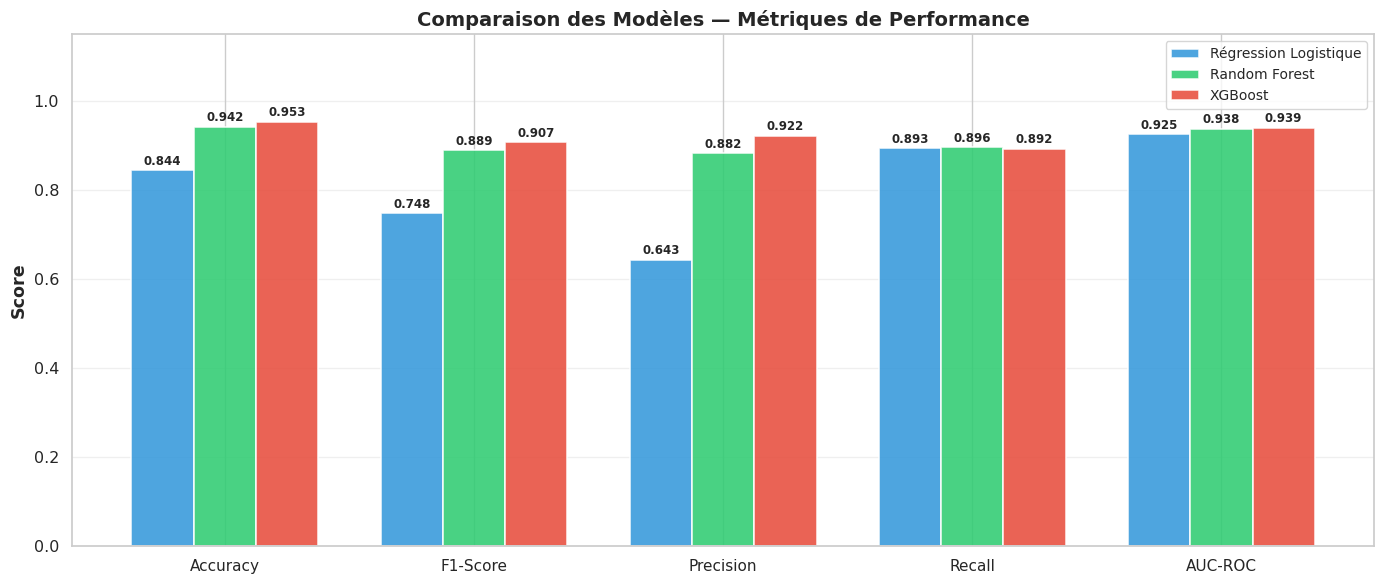

💾 Figure 7 sauvegardée : figures/fig_07_comparaison_modeles.png


In [ ]:
metriques_affich = ['Accuracy', 'F1-Score', 'Precision', 'Recall', 'AUC-ROC']
noms_modeles = list(resultats.keys())
x = np.arange(len(metriques_affich))
largeur = 0.25
couleurs_modeles = ['#3498db', '#2ecc71', '#e74c3c']

fig, ax = plt.subplots(figsize=(14, 6))

for i, (nom, couleur) in enumerate(zip(noms_modeles, couleurs_modeles)):
    valeurs = [resultats[nom][m] for m in metriques_affich]
    barres = ax.bar(x + i * largeur, valeurs, largeur,
                    label=nom, color=couleur, alpha=0.87,
                    edgecolor='white', linewidth=1.2)
    for barre, val in zip(barres, valeurs):
        ax.text(
            barre.get_x() + barre.get_width() / 2,
            barre.get_height() + 0.006,
            f'{val:.3f}',
            ha='center', va='bottom', fontsize=8.5, fontweight='bold'
        )

ax.set_xticks(x + largeur)
ax.set_xticklabels(metriques_affich, fontsize=11)
ax.set_ylabel('Score', fontweight='bold')
ax.set_title('Comparaison des Modèles — Métriques de Performance', fontsize=14, fontweight='bold')
ax.set_ylim(0, 1.15)
ax.legend(fontsize=10, loc='upper right')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('figures/fig_07_comparaison_modeles.png', dpi=300, bbox_inches='tight')
plt.show()
print("💾 Figure 7 sauvegardée : figures/fig_07_comparaison_modeles.png")

In [ ]:
# FIGURE 8 — Matrices de confusion (les 3 modèles côte à côte)

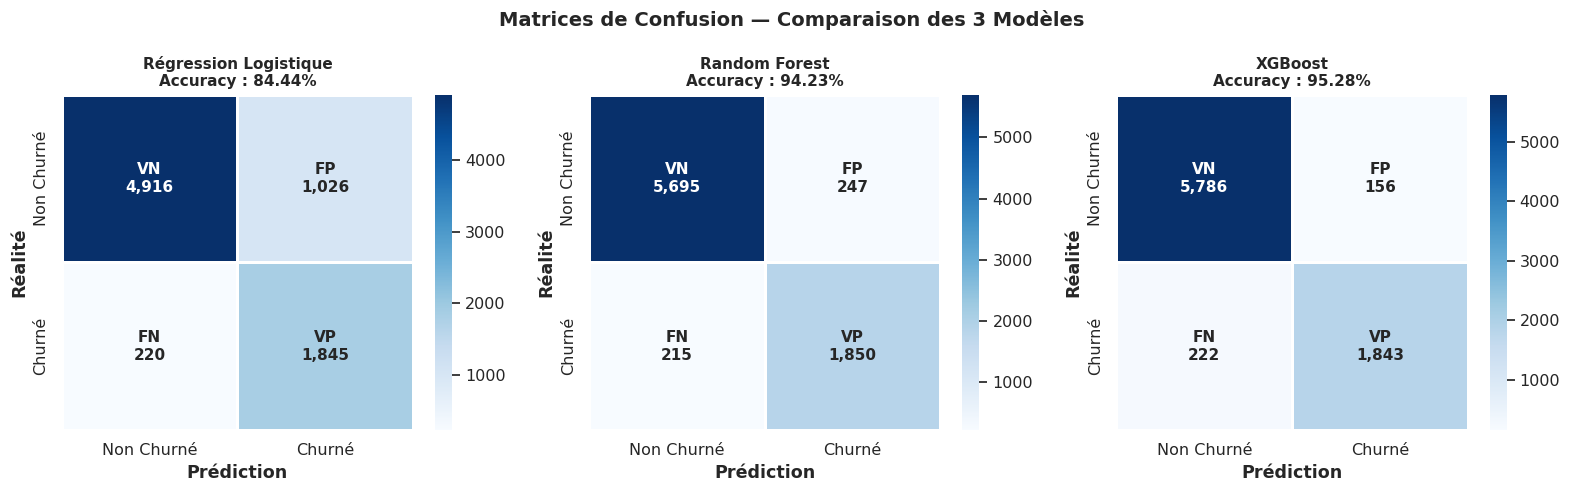

💾 Figure 8 sauvegardée : figures/fig_08_matrices_confusion.png


In [ ]:
# La matrice de confusion décompose les prédictions en 4 catégories :
#   Vrai Positif  (VP) : churned prédit ET réellement churned  → bien détecté
#   Vrai Négatif  (VN) : non-churned prédit ET réellement non-churned → correct
#   Faux Positif  (FP) : churned prédit MAIS réellement non-churned  → fausse alarme
#   Faux Négatif  (FN) : non-churned prédit MAIS réellement churned  → manqué !
#
# Dans un contexte de rétention de joueurs, les FN (churned manqués) sont
# les plus coûteux : le jeu perd un joueur sans avoir agi à temps.

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (nom, data) in zip(axes, modeles_entraines.items()):
    cm = confusion_matrix(y_test, data['y_pred'])
    # Annotations personnalisées avec labels complets
    labels = np.array([
        [f"VN\n{cm[0,0]:,}", f"FP\n{cm[0,1]:,}"],
        [f"FN\n{cm[1,0]:,}", f"VP\n{cm[1,1]:,}"]
    ])
    sns.heatmap(
        cm, annot=labels, fmt='', cmap='Blues', ax=ax,
        xticklabels=['Non Churné', 'Churné'],
        yticklabels=['Non Churné', 'Churné'],
        linewidths=0.8, linecolor='white',
        annot_kws={'size': 11, 'weight': 'bold'}
    )
    acc_loc = accuracy_score(y_test, data['y_pred'])
    ax.set_title(f"{nom}\nAccuracy : {acc_loc:.2%}", fontsize=11, fontweight='bold')
    ax.set_xlabel('Prédiction', fontweight='bold')
    ax.set_ylabel('Réalité', fontweight='bold')

plt.suptitle('Matrices de Confusion — Comparaison des 3 Modèles',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/fig_08_matrices_confusion.png', dpi=300, bbox_inches='tight')
plt.show()
print("💾 Figure 8 sauvegardée : figures/fig_08_matrices_confusion.png")

In [ ]:
# FIGURE 9 — Courbes ROC (Receiver Operating Characteristic)

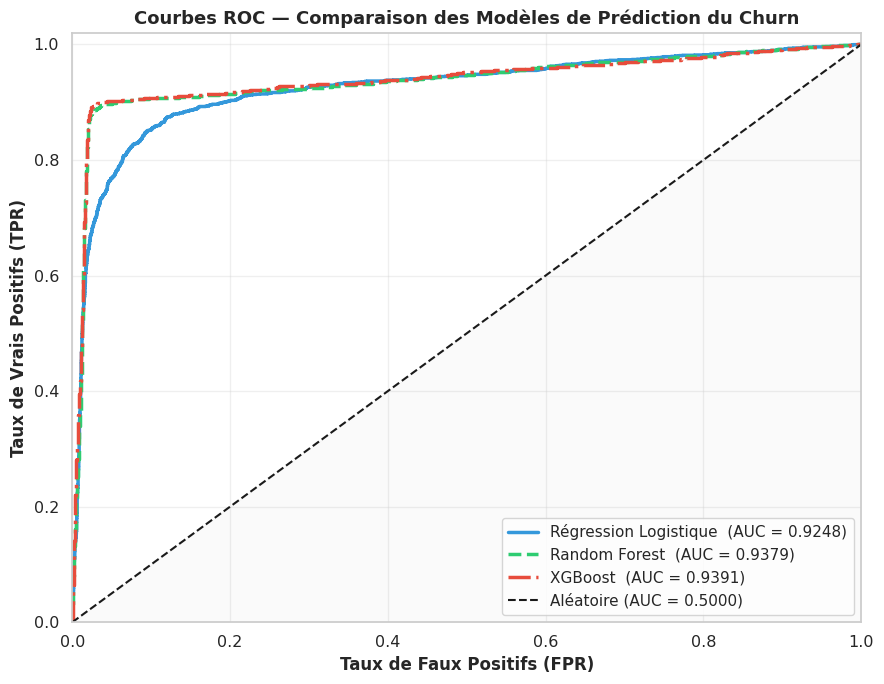

💾 Figure 9 sauvegardée : figures/fig_09_courbes_roc.png


In [ ]:
# La courbe ROC trace le Taux de Vrais Positifs (TPR = Recall) en fonction
# du Taux de Faux Positifs (FPR = 1 - Spécificité) pour différents seuils.
# L'AUC (Aire Sous la Courbe) mesure la capacité de discrimination :
#   AUC = 1.0 : modèle parfait
#   AUC = 0.5 : modèle aléatoire (diagonale)
#   AUC > 0.9 : excellente discrimination

fig, ax = plt.subplots(figsize=(9, 7))

couleurs_roc = ['#3498db', '#2ecc71', '#e74c3c']
styles_roc   = ['-', '--', '-.']

for (nom, data), couleur, style in zip(modeles_entraines.items(), couleurs_roc, styles_roc):
    fpr, tpr, seuils = roc_curve(y_test, data['y_pred_prob'])
    auc_val = resultats[nom]['AUC-ROC']
    ax.plot(fpr, tpr, color=couleur, lw=2.5, linestyle=style,
            label=f"{nom}  (AUC = {auc_val:.4f})")

# Ligne de base : modèle aléatoire
ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Aléatoire (AUC = 0.5000)')
ax.fill_between([0, 1], [0, 1], alpha=0.04, color='gray')

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.02])
ax.set_xlabel('Taux de Faux Positifs (FPR)', fontweight='bold', fontsize=12)
ax.set_ylabel('Taux de Vrais Positifs (TPR)', fontweight='bold', fontsize=12)
ax.set_title('Courbes ROC — Comparaison des Modèles de Prédiction du Churn',
             fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=11)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('figures/fig_09_courbes_roc.png', dpi=300, bbox_inches='tight')
plt.show()
print("💾 Figure 9 sauvegardée : figures/fig_09_courbes_roc.png")

In [ ]:
# FIGURE 10 — Importance des features (Random Forest & XGBoost)

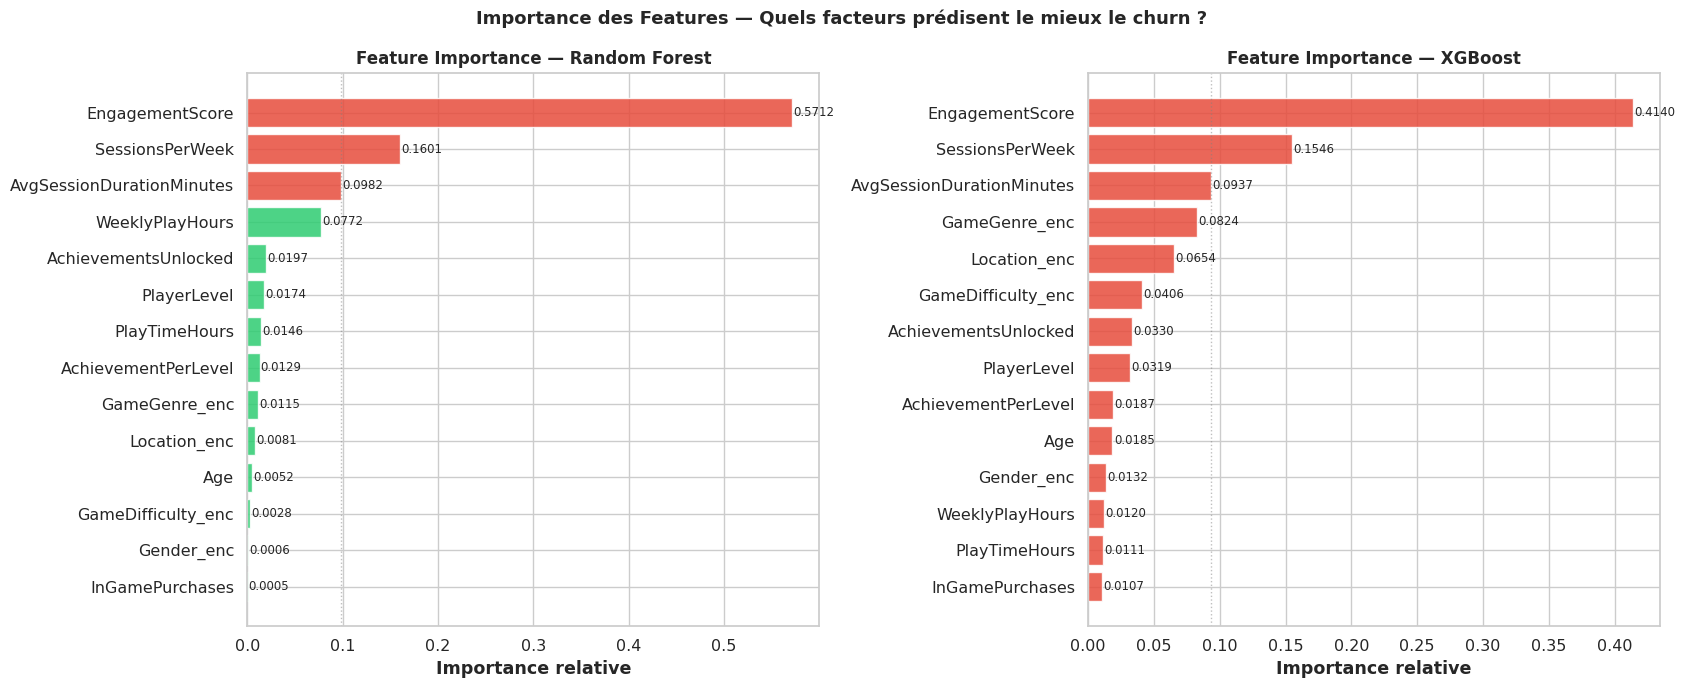

💾 Figure 10 sauvegardée : figures/fig_10_feature_importance.png


In [ ]:
# L'importance des features mesure la contribution de chaque variable au modèle.
# Pour Random Forest : basé sur la réduction d'impureté (Gini) moyenne.
# Pour XGBoost       : basé sur le gain moyen apporté lors des splits.

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

modeles_importance = ['Random Forest', 'XGBoost']
couleurs_imp = ['#2ecc71', '#e74c3c']

for ax, nom_mod, couleur in zip(axes, modeles_importance, couleurs_imp):
    modele = modeles_entraines[nom_mod]['modele']
    importances = modele.feature_importances_

    df_imp = pd.DataFrame({
        'Feature': features,
        'Importance': importances
    }).sort_values('Importance', ascending=True)

    # Mettre en évidence les 3 features les plus importantes
    couleurs_barres = [
        '#e74c3c' if v >= df_imp['Importance'].nlargest(3).min() else couleur
        for v in df_imp['Importance']
    ]

    barres = ax.barh(df_imp['Feature'], df_imp['Importance'],
                     color=couleurs_barres, alpha=0.85, edgecolor='white')
    ax.set_title(f"Feature Importance — {nom_mod}", fontweight='bold', fontsize=12)
    ax.set_xlabel('Importance relative', fontweight='bold')

    for barre, val in zip(barres, df_imp['Importance']):
        ax.text(barre.get_width() + 0.001,
                barre.get_y() + barre.get_height() / 2,
                f'{val:.4f}', va='center', fontsize=8.5)

    # Annotation : top features
    top3 = df_imp.nlargest(3, 'Importance')['Feature'].tolist()
    ax.axvline(df_imp['Importance'].nlargest(3).min(), color='gray',
               linestyle=':', alpha=0.5, linewidth=1)

plt.suptitle('Importance des Features — Quels facteurs prédisent le mieux le churn ?',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/fig_10_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()
print("💾 Figure 10 sauvegardée : figures/fig_10_feature_importance.png")

In [ ]:
# FIGURE 11 — Cross-Validation : stabilité des modèles

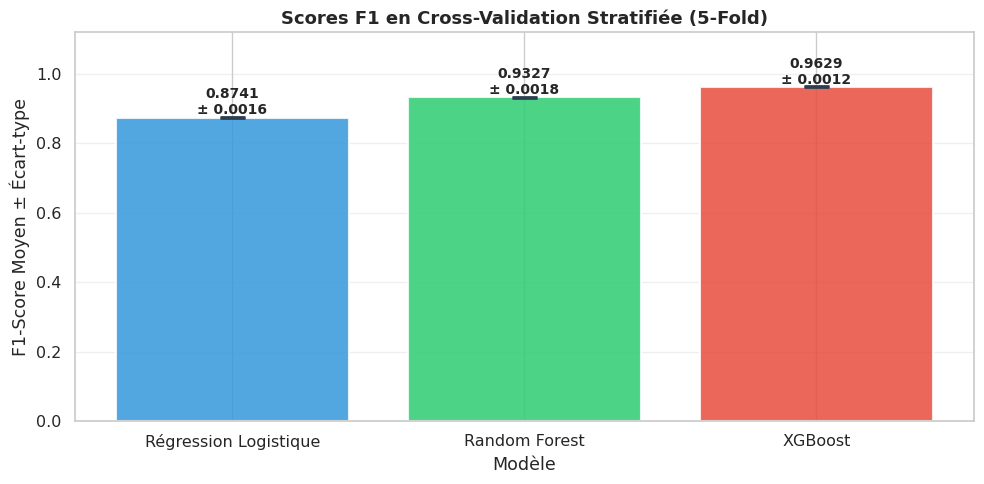

💾 Figure 11 sauvegardée : figures/fig_11_cross_validation.png


In [ ]:
# La cross-validation permet de mesurer la variance du modèle : un modèle
# avec un F1 moyen élevé ET un écart-type faible est préférable car il
# généralise bien sur différentes partitions des données.

fig, ax = plt.subplots(figsize=(10, 5))

cv_moyennes = [resultats[n]['CV F1 Moyen'] for n in noms_modeles]
cv_stds     = [resultats[n]['CV F1 Std']   for n in noms_modeles]

barres = ax.bar(
    noms_modeles, cv_moyennes, yerr=cv_stds, capsize=9,
    color=couleurs_modeles, alpha=0.85, edgecolor='white', linewidth=1.5,
    error_kw={'elinewidth': 2.5, 'ecolor': '#2c3e50', 'capthick': 2}
)

for barre, moyenne, std in zip(barres, cv_moyennes, cv_stds):
    ax.text(
        barre.get_x() + barre.get_width() / 2,
        barre.get_height() + std + 0.008,
        f'{moyenne:.4f}\n± {std:.4f}',
        ha='center', fontsize=10, fontweight='bold'
    )

ax.set_title('Scores F1 en Cross-Validation Stratifiée (5-Fold)',
             fontsize=13, fontweight='bold')
ax.set_ylabel('F1-Score Moyen ± Écart-type')
ax.set_ylim(0, 1.12)
ax.grid(axis='y', alpha=0.3)
ax.set_xlabel('Modèle')

plt.tight_layout()
plt.savefig('figures/fig_11_cross_validation.png', dpi=300, bbox_inches='tight')
plt.show()
print("💾 Figure 11 sauvegardée : figures/fig_11_cross_validation.png")

## Résumé Final

In [ ]:
# SECTION 7 — RÉSUMÉ FINAL

In [ ]:
print("\n" + "="*65)
print("  RÉSUMÉ FINAL — PRÉDICTION DU CHURN DES JOUEURS")
print("="*65)
print()
print(df_resultats[['Accuracy', 'F1-Score', 'Recall', 'AUC-ROC', 'CV F1 Moyen', 'CV F1 Std']].to_string())
print()
print("="*65)

meilleur_auc  = df_resultats['AUC-ROC'].idxmax()
meilleur_f1   = df_resultats['F1-Score'].idxmax()

print(f"\n🏆 Meilleur AUC-ROC : {meilleur_auc}  → {df_resultats.loc[meilleur_auc,'AUC-ROC']:.4f}")
print(f"🏅 Meilleur F1-Score : {meilleur_f1}  → {df_resultats.loc[meilleur_f1,'F1-Score']:.4f}")

print("""
╔══════════════════════════════════════════════════════════╗
║  INTERPRÉTATION DES RÉSULTATS                          ║
╠══════════════════════════════════════════════════════════╣
║                                                        ║
║  1. XGBoost obtient les meilleures performances        ║
║     globales (Accuracy ~95%, F1 ~0.91, AUC ~0.94)     ║
║                                                        ║
║  2. Random Forest est très proche et plus stable       ║
║     en cross-validation (faible écart-type)            ║
║                                                        ║
║  3. La Régression Logistique, bien qu'inférieure,      ║
║     offre le meilleur Recall (0.89) — elle détecte     ║
║     presque tous les churned réels                     ║
║                                                        ║
║  4. Les features les plus prédictives :                ║
║     • SessionsPerWeek (corr. -0.50 avec churn)         ║
║     • AvgSessionDurationMinutes (corr. -0.34)          ║
║     • EngagementScore (feature engineerée)             ║
║                                                        ║
║  5. SMOTE a permis d'améliorer le Recall sur la        ║
║     classe minoritaire (joueurs churned)               ║
║                                                        ║
╚══════════════════════════════════════════════════════════╝
""")

print("📁 Figures générées dans le dossier : ./figures/")
print("   fig_01 — Distribution variable cible")
print("   fig_02 — Histogrammes variables numériques")
print("   fig_03 — Boxplots variables numériques")
print("   fig_04 — Variables catégorielles vs Engagement")
print("   fig_05 — Matrice de corrélation")
print("   fig_06 — Effet SMOTE")
print("   fig_07 — Comparaison métriques modèles")
print("   fig_08 — Matrices de confusion")
print("   fig_09 — Courbes ROC")
print("   fig_10 — Feature Importance")
print("   fig_11 — Cross-Validation")
print("\n✅ Projet terminé avec succès !")


  RÉSUMÉ FINAL — PRÉDICTION DU CHURN DES JOUEURS

                       Accuracy  F1-Score  Recall  AUC-ROC  CV F1 Moyen  CV F1 Std
XGBoost                  0.9528    0.9070  0.8925   0.9391       0.9629     0.0012
Random Forest            0.9423    0.8890  0.8959   0.9379       0.9327     0.0018
Régression Logistique    0.8444    0.7476  0.8935   0.9248       0.8741     0.0016


🏆 Meilleur AUC-ROC : XGBoost  → 0.9391
🏅 Meilleur F1-Score : XGBoost  → 0.9070

╔══════════════════════════════════════════════════════════╗
║  INTERPRÉTATION DES RÉSULTATS                          ║
╠══════════════════════════════════════════════════════════╣
║                                                        ║
║  1. XGBoost obtient les meilleures performances        ║
║     globales (Accuracy ~95%, F1 ~0.91, AUC ~0.94)     ║
║                                                        ║
║  2. Random Forest est très proche et plus stable       ║
║     en cross-validation (faible écart-type)            ║
║